# Replication demo: brain encoding across languages with one model (DistilmBERT)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Andrea-de-Varda/multilingual-models-brain/blob/revision/demo/encoding_demo.ipynb)

This notebook reproduces, for one of the 20 language models of the paper (DistilmBERT), the core Study I analyses of *A shared meaning component across languages in the human brain* (de Varda, Malik-Moraleda, Tuckute & Fedorenko, Nature Neuroscience):

- **WITHIN**: encoding models trained and tested within each of 12 languages, across participants (Figure 2A, top);
- **ACROSS**: encoding models trained on 11 languages and transferred zero-shot to the 12th (Figure 2A, bottom);
- **significance** against circularly shifted fMRI responses (Methods, "Significance testing").

Everything is computed from scratch from the files in the repository: the word-by-word transcriptions of the passages (`transcribed/`) and the fMRI time series of the language network (`data/dict_fROI`). The functions in `demo_utils.py` are copied from the analysis scripts of the paper (`get_model_embeddings.py`, `fit_encoding.py`, `plot_encoding_*.py`).

**Runtime.** About 5 minutes to extract the embeddings on a laptop CPU (1 minute on a GPU), then about 1 minute (GPU) or 10 minutes (CPU) for the encoding models. A command-line version is `python demo/run_demo.py`.


## 0. Setup
On Google Colab, the next cell downloads the repository and installs the two packages that are not preinstalled. Locally, install the environment described in the README (`requirements.txt`) and start Jupyter from the repository root or from `demo/`.

In [1]:
import os, sys
if "google.colab" in sys.modules:
    !git clone -q --depth 1 -b revision https://github.com/Andrea-de-Varda/multilingual-models-brain.git
    !pip -q install himalaya==0.4.6 transformers==4.45.2
    os.chdir("multilingual-models-brain/demo")
sys.path.insert(0, os.path.abspath("." if os.path.isfile("demo_utils.py") else "demo"))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import demo_utils as du
print("himalaya backend:", du.set_backend())   # GPU if available, otherwise PyTorch on CPU

himalaya backend: torch_cuda


## 1. fMRI data
For each of the 12 languages, two native speakers listened to a ~4.5-minute passage of *Alice in Wonderland*. For each participant we have the time series (130 volumes, one every 2 s, already shifted by 6 s to account for the hemodynamic delay) of each of the five left-hemisphere language fROIs and of their average (`'all'`, the network-level response used in the main analyses).

fROIs: ['Lang_LH_AntTemp', 'Lang_LH_IFG', 'Lang_LH_IFGorb', 'Lang_LH_MFG', 'Lang_LH_PostTemp', 'all']


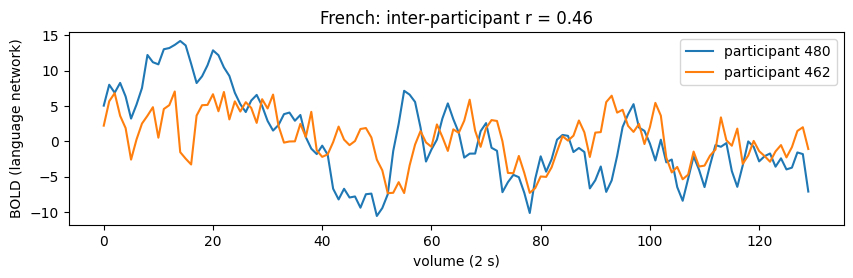

In [2]:
d = du.load_fmri()
lang = "French"                      # try another language: Afrikaans, Dutch, Farsi, Lithuanian, Marathi, ...
p1, p2 = d[lang].keys()
print("fROIs:", list(d[lang][p1].keys()))
from scipy.stats import pearsonr
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(d[lang][p1]["all"], label=f"participant {p1}"); ax.plot(d[lang][p2]["all"], label=f"participant {p2}")
ax.set(xlabel="volume (2 s)", ylabel="BOLD (language network)", title=f"{lang}: inter-participant r = {pearsonr(d[lang][p1]['all'], d[lang][p2]['all'])[0]:.2f}")
ax.legend(); plt.show()

## 2. Word embeddings
The transcriptions (obtained with Whisper-timestamped) give each word with its onset and offset. DistilmBERT processes the text with a sliding window of 100 words; for each word we keep the embedding it receives as the last word of its window, so that the (bidirectional) model only sees the preceding context. We keep all 7 hidden layers (layer 0 is the input embedding layer). Embeddings are cached in `demo/cache/`.

In [3]:
emb = du.get_all_embeddings(os.path.join(os.path.dirname(du.__file__), "cache"))
print({l: e[6].shape for l, e in emb.items()})

  Afrikaans   674 words


  Dutch       642 words


  Farsi       723 words


  French      760 words


  Lithuanian  530 words


...

  Romanian    666 words


  Spanish     576 words


  Tamil       319 words


  Turkish     456 words


  Vietnamese  740 words
{'af': (674, 768), 'nl': (642, 768), 'fa': (723, 768), 'fr': (760, 768), 'lt': (530, 768), 'mr': (442, 768), 'no': (579, 768), 'ro': (666, 768), 'es': (576, 768), 'ta': (319, 768), 'tr': (456, 768), 'vi': (740, 768)}


## 3. Alignment with the fMRI volumes
The embedding of each volume is the average of the embeddings of the words whose offset falls within that 2-s interval (volumes without words receive the average embedding).

In [4]:
X_layers = {layer: {l: du.preproc_align(l, emb[l][layer]) for l in du.LANGS} for layer in range(7)}
print(X_layers[6]["fr"].shape)   # 130 volumes x 768 dimensions

(130, 768)


## 4. WITHIN encoding models
For each language, ridge regression maps the embeddings onto the brain response with 10-fold sequential cross-validation; the model is trained on 90% of the data of one participant and tested on the held-out 10% of the **other** participant, in both directions. Below, all layers, compared with the values in the paper (Source Data Fig. 2, sheet Fig2B_layerwise).

In [5]:
PAPER_WITHIN = [0.030445, 0.083529, 0.109169, 0.131199, 0.142502, 0.155845, 0.173093]
PAPER_ACROSS = [0.001822, 0.005299, 0.039226, 0.081957, 0.139847, 0.114869, 0.097520]
within = {layer: du.within_encoding(X_layers[layer], d) for layer in range(7)}
res = pd.DataFrame({"layer": range(7), "r (this run)": [within[l].m.mean() for l in range(7)], "r (paper)": PAPER_WITHIN})
res

,layer,r (this run),r (paper)
0,0,0.030446,0.030445
1,1,0.083529,0.083529
2,2,0.109170,0.109169
3,3,0.131199,0.131199
4,4,0.142502,0.142502
5,5,0.155845,0.155845
6,6,0.173093,0.173093


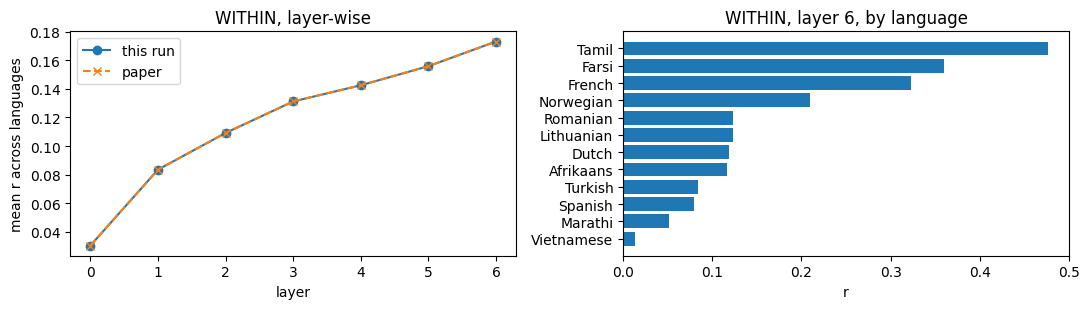

In [6]:
best_w = du.best_layer(within, "m")
df = within[best_w].assign(language=lambda x: x.lang.map(du.LANGS)).sort_values("m")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(res.layer, res["r (this run)"], "o-", label="this run"); ax[0].plot(res.layer, res["r (paper)"], "x--", label="paper")
ax[0].set(xlabel="layer", ylabel="mean r across languages", title="WITHIN, layer-wise"); ax[0].legend()
ax[1].barh(df.language, df.m); ax[1].set(xlabel="r", title=f"WITHIN, layer {best_w}, by language")
plt.tight_layout(); plt.show()

## 5. ACROSS encoding models (zero-shot transfer to a new language)
For each target language, the model is trained on 90% of the data of all the **other 11 languages** (both participants) and predicts the held-out 10% of the target language; this is repeated over the 10 folds and the prediction is correlated with each participant's response. Choose the layer below (`LAYER = 4` is the best ACROSS layer of DistilmBERT in the paper). One layer takes about 1 minute on a GPU and a few minutes on a CPU.

ACROSS, layer 4: mean r = 0.1398   (paper: 0.1398)


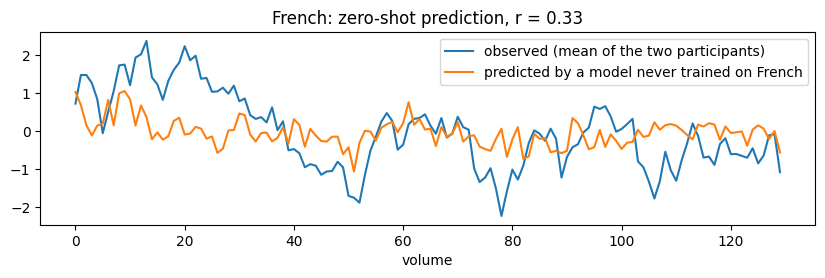

,language,r
0,Afrikaans,0.152
1,Dutch,0.078
2,Farsi,0.161
3,French,0.327
4,Lithuanian,0.162
5,Marathi,-0.053
6,Norwegian,0.008
7,Romanian,0.139
8,Spanish,0.216
9,Tamil,0.148


In [7]:
LAYER = 4
across, preds = du.across_encoding(X_layers[LAYER], d, return_predictions=True)
print(f"ACROSS, layer {LAYER}: mean r = {across.r.mean():.4f}   (paper: {PAPER_ACROSS[LAYER]:.4f})")
target = "fr"
pred, t1, t2 = preds[target]
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(0.5 * (t1 + t2), label="observed (mean of the two participants)"); ax.plot(pred, label="predicted by a model never trained on French")
ax.set(xlabel="volume", title=f"{du.LANGS[target]}: zero-shot prediction, r = {across.set_index('target_lang').r[target]:.2f}"); ax.legend(); plt.show()
across.assign(language=lambda x: x.target_lang.map(du.LANGS))[["language", "r"]].round(3)

## 6. Statistical significance
The same models are refit after circularly shifting the fMRI time series by 26, 52, 78 and 104 volumes, which destroys the correspondence with the stimulus but keeps the temporal autocorrelation. For each language the correlation of the real model is compared with that of the shifted models (Fisher r-to-z difference with n = 130), and the z values are combined with Stouffer's method, first across languages and then across the four shifts; as in the paper, the best layer is selected separately for the real and for each shifted model. (For ACROSS, only the chosen layer is evaluated here.)

In [8]:
shifted_w = {s: {l: du.within_encoding(X_layers[l], d, shift=s) for l in range(7)} for s in du.SHIFTS}
z, p = du.significance(within, shifted_w, "m")
print(f"WITHIN : z = {z:.2f}, p = {p:.2g}   (paper: z = 3.32, p = 9.0e-04)")
shifted_a = {s: {LAYER: du.across_encoding(X_layers[LAYER], d, shift=s)} for s in du.SHIFTS}
z, p = du.significance({LAYER: across}, shifted_a, "r")
print(f"ACROSS : z = {z:.2f}, p = {p:.2g}   (paper, best layer with all layers evaluated: z = 6.90, p = 5.1e-12)")

WITHIN : z = 3.32, p = 0.0009   (paper: z = 3.32, p = 9.0e-04)


ACROSS : z = 4.57, p = 5e-06   (paper, best layer with all layers evaluated: z = 6.90, p = 5.1e-12)


## What next
- All 20 models, all fROIs and the control networks: `fit_encoding.py` (see README for the modes) and `plot_encoding_mono.py` / `plot_encoding_multi.py`.
- Study II (transfer to 9 new languages from four training datasets), Study III (perturbations) and Study IV (INLP ablation): see the README.
